In [1]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import pickle

In [2]:
# https://stackoverflow.com/questions/50506076/is-there-an-efficient-way-to-store-2d-plots-as-a-vector-graphic-in-python

import matplotlib as mpl

mpl.use('svg')
new_rc_params = {
    "font.size": 9,
    "font.serif": [],
    "svg.fonttype": 'none'} # to store text as text, not as path
mpl.rcParams.update(new_rc_params)

import matplotlib.pyplot as plt
import seaborn as sns

# Disease Classification (Split by Patient)

In [7]:
df_full = pd.read_csv("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/notes/xhs-disease-classification-results.csv")

df = df_full[df_full["test"] == "Patient-Split, Sample-Bag"].reset_index(drop=True)  # patient split, sample-level bag
df = df[df["method"] != "TERRA-nbr"].replace({"method": {"TERRA-cell": "TERRA"}}).reset_index(drop=True)
df['dataset'] = 'Patient'

df

,dataset,test,method,fold,BAG_Accuracy,BAG_Macro-F1,BAG_AUC-ROC,CELL_Accuracy,CELL_Macro-F1,CELL_AUC-ROC
0,Patient,"Patient-Split, Sample-Bag",TERRA,1,0.736842,0.680135,0.738636,0.707922,0.693668,0.770541
1,Patient,"Patient-Split, Sample-Bag",TERRA,2,0.800000,0.740125,0.801587,0.794934,0.725642,0.818032
2,Patient,"Patient-Split, Sample-Bag",TERRA,3,0.647059,0.635714,0.833333,0.713538,0.707505,0.770207
3,Patient,"Patient-Split, Sample-Bag",TERRA,4,0.722222,0.672727,0.792208,0.701273,0.661411,0.774404
4,Patient,"Patient-Split, Sample-Bag",CellPLM,1,0.789474,0.756410,0.943182,0.676302,0.669573,0.762066
5,Patient,"Patient-Split, Sample-Bag",CellPLM,2,0.800000,0.761905,0.801587,0.695696,0.627295,0.720680
6,Patient,"Patient-Split, Sample-Bag",CellPLM,3,0.529412,0.433333,0.861111,0.609632,0.598244,0.638998
7,Patient,"Patient-Split, Sample-Bag",CellPLM,4,0.722222,0.698997,0.805195,0.599943,0.567879,0.660361
8,Patient,"Patient-Split, Sample-Bag",Nicheformer,1,0.526316,0.424242,0.727273,0.544676,0.532212,0.611276
9,Patient,"Patient-Split, Sample-Bag",Nicheformer,2,0.640000,0.532225,0.722222,0.670516,0.576563,0.694186


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D
from collections import OrderedDict

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 21,
    "axes.titlesize": 21,
    "axes.labelsize": 21,
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 17,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sns.set(style="white")

# ----------------------------
# Explicit colors (editable)
# ----------------------------
SET2_HEX = [
    "#66c2a5",  # TERRA
    "#fc8d62",  # CellPLM
    "#8da0cb",  # Nicheformer
    "#e78ac3",  # scGPT-spatial
    "#ffd92f",  # Novae
]

methods = list(df["method"].unique())
datasets = list(df["dataset"].unique())

METHOD_COLORS = {
    method: SET2_HEX[i]
    for i, method in enumerate(methods)
}

# ----------------------------
# Plot
# ----------------------------
for metric in ["CELL_Accuracy", "CELL_AUC-ROC"]:

    # Compact figure
    fig, ax = plt.subplots(figsize=(4.2, 2.0))

    BAR_WIDTH = 0.36

    # ---- BARPLOT ----
    sns.barplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        dodge=True,
        ci=None,
        width=BAR_WIDTH,
        palette=METHOD_COLORS,
        edgecolor="black",
        linewidth=0.85,
        ax=ax
    )

    # ---- DOTS (ALIGNED TO BAR CENTERS) ----
    bar_index = 0
    for dataset in datasets:
        for method in methods:

            subset = df[
                (df["dataset"] == dataset) &
                (df["method"] == method)
            ]

            if subset.empty:
                bar_index += 1
                continue

            patch = ax.patches[bar_index]
            x_center = patch.get_x() + patch.get_width() / 2

            ax.scatter(
                np.full(len(subset), x_center),
                subset[metric].values,
                s=3.6**2,
                marker="o",
                facecolor=METHOD_COLORS[method],
                edgecolor="black",
                linewidth=0.45,
                alpha=0.75,
                zorder=10
            )

            bar_index += 1

    # ---- LEGEND (DOT-ONLY, SINGLE ROW) ----
    if ax.legend_ is not None:
        ax.legend_.remove()

    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color="w",
            label=method,
            markerfacecolor=METHOD_COLORS[method],
            markeredgecolor="black",
            markersize=5.5
        )
        for method in methods
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.36),
        ncol=len(legend_handles),
        frameon=False,
        handletextpad=0.4,
        columnspacing=1.0
    )
    ax.set_xticks([])
    ax.set_xticklabels([])

    # ---- AXES ----
    if "Accuracy" in metric:
        metric_name = "Accuracy"
    if "Macro-F1" in metric:
        metric_name = "Macro-F1"
    if "AUC-ROC" in metric:
        metric_name = "AUC-ROC"
    ax.set_title(f"Patient ({metric_name})", pad=3)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_ylim(0.0, 1.0)

    # ---- REMOVE CATEGORY WHITESPACE (CRITICAL) ----
    left = min(p.get_x() for p in ax.patches)
    right = max(p.get_x() + p.get_width() for p in ax.patches)
    ax.set_xlim(left - 0.01, right + 0.01)
    ax.margins(x=0)

    # ---- CLEAN LOOK ----
    sns.despine(ax=ax, top=True, right=True)
    ax.grid(False)

    plt.tight_layout(pad=0.01)
    plt.subplots_adjust(bottom=0.36)

    # ---- SAVE ----
    plt.savefig(
        f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/figures/disease-classification_patient_{metric_name}.svg",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

/tmp/ipykernel_2459133/1877059481.py:55: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
/tmp/ipykernel_2459133/1877059481.py:55: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


# Disease Classification (Split by Sample)

In [9]:
df_full = pd.read_csv("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/notes/xhs-disease-classification-results.csv")

df = df_full[df_full["test"] == "Sample-Split, Sample-Bag"].reset_index(drop=True)  # sample split, sample-level bag
df = df[df["method"] != "TERRA-nbr"].replace({"method": {"TERRA-cell": "TERRA"}}).reset_index(drop=True)
df['dataset'] = 'Patient'

df

,dataset,test,method,fold,BAG_Accuracy,BAG_Macro-F1,BAG_AUC-ROC,CELL_Accuracy,CELL_Macro-F1,CELL_AUC-ROC
0,Patient,"Sample-Split, Sample-Bag",TERRA,1,0.750000,0.686520,0.989583,0.798192,0.770488,0.872721
1,Patient,"Sample-Split, Sample-Bag",TERRA,2,0.850000,0.846547,0.937500,0.747687,0.722616,0.788652
2,Patient,"Sample-Split, Sample-Bag",TERRA,3,0.578947,0.457143,0.702381,0.730979,0.687680,0.813489
3,Patient,"Sample-Split, Sample-Bag",TERRA,4,0.850000,0.829060,0.843750,0.795888,0.751800,0.840223
4,Patient,"Sample-Split, Sample-Bag",CellPLM,1,0.750000,0.733333,0.885417,0.737356,0.703309,0.786647
5,Patient,"Sample-Split, Sample-Bag",CellPLM,2,0.850000,0.840000,0.958333,0.726734,0.702737,0.740235
6,Patient,"Sample-Split, Sample-Bag",CellPLM,3,0.631579,0.490421,0.619048,0.643085,0.610771,0.704858
7,Patient,"Sample-Split, Sample-Bag",CellPLM,4,0.700000,0.642857,0.760417,0.746652,0.694490,0.775982
8,Patient,"Sample-Split, Sample-Bag",Nicheformer,1,0.850000,0.840000,0.937500,0.717510,0.695418,0.800387
9,Patient,"Sample-Split, Sample-Bag",Nicheformer,2,0.800000,0.791667,0.947917,0.699181,0.680731,0.749195


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D
from collections import OrderedDict

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 21,
    "axes.titlesize": 21,
    "axes.labelsize": 21,
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 17,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sns.set(style="white")

# ----------------------------
# Explicit colors (editable)
# ----------------------------
SET2_HEX = [
    "#66c2a5",  # TERRA
    "#fc8d62",  # CellPLM
    "#8da0cb",  # Nicheformer
    "#e78ac3",  # scGPT-spatial
    "#ffd92f",  # Novae
]

methods = list(df["method"].unique())
datasets = list(df["dataset"].unique())

METHOD_COLORS = {
    method: SET2_HEX[i]
    for i, method in enumerate(methods)
}

# ----------------------------
# Plot
# ----------------------------
for metric in ["CELL_Accuracy", "CELL_AUC-ROC"]:

    # Compact figure
    fig, ax = plt.subplots(figsize=(4.2, 2.0))

    BAR_WIDTH = 0.36

    # ---- BARPLOT ----
    sns.barplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        dodge=True,
    )
    # Compact figure
    fig, ax = plt.subplots(figsize=(4.2, 2.0))

    BAR_WIDTH = 0.36

    # ---- BARPLOT ----
    sns.barplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        dodge=True,
        ci=None,
        width=BAR_WIDTH,
        palette=METHOD_COLORS,
        edgecolor="black",
        linewidth=0.85,
        ax=ax
    )

    # ---- DOTS (ALIGNED TO BAR CENTERS) ----
    bar_index = 0
    for dataset in datasets:
        for method in methods:

            subset = df[
                (df["dataset"] == dataset) &
                (df["method"] == method)
            ]

            if subset.empty:
                bar_index += 1
                continue

            patch = ax.patches[bar_index]
            x_center = patch.get_x() + patch.get_width() / 2

            ax.scatter(
                np.full(len(subset), x_center),
                subset[metric].values,
                s=3.6**2,
                marker="o",
                facecolor=METHOD_COLORS[method],
                edgecolor="black",
                linewidth=0.45,
                alpha=0.75,
                zorder=10
            )

            bar_index += 1

    # ---- LEGEND (DOT-ONLY, SINGLE ROW) ----
    if ax.legend_ is not None:
        ax.legend_.remove()

    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color="w",
            label=method,
            markerfacecolor=METHOD_COLORS[method],
            markeredgecolor="black",
            markersize=5.5
        )
        for method in methods
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.36),
        ncol=len(legend_handles),
        frameon=False,
        handletextpad=0.4,
        columnspacing=1.0
    )
    ax.set_xticks([])
    ax.set_xticklabels([])

    # ---- AXES ----
    if "Accuracy" in metric:
        metric_name = "Accuracy"
    if "Macro-F1" in metric:
        metric_name = "Macro-F1"
    if "AUC-ROC" in metric:
        metric_name = "AUC-ROC"
    ax.set_title(f"Sample ({metric_name})", pad=3)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_ylim(0.0, 1.0)
    # ---- REMOVE CATEGORY WHITESPACE (CRITICAL) ----
    left = min(p.get_x() for p in ax.patches)
    right = max(p.get_x() + p.get_width() for p in ax.patches)
    ax.set_xlim(left - 0.01, right + 0.01)
    ax.margins(x=0)

    # ---- CLEAN LOOK ----
    sns.despine(ax=ax, top=True, right=True)
    ax.grid(False)

    plt.tight_layout(pad=0.01)
    plt.subplots_adjust(bottom=0.36)

    # ---- SAVE ----
    plt.savefig(
        f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/figures/disease-classification_sample_{metric_name}.svg",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

/tmp/ipykernel_2459133/2746065269.py:68: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
/tmp/ipykernel_2459133/2746065269.py:68: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


# Disease Classification Distribution

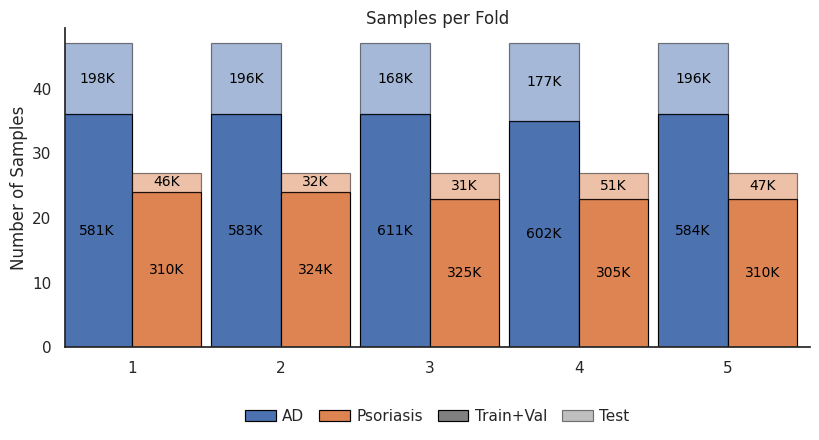

In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from collections import OrderedDict
from matplotlib.lines import Line2D
import numpy as np

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 21,
    "axes.titlesize": 21,
    "axes.labelsize": 21,
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 17,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sns.set(style="white")

# fold, disease, train_samples, test_samples, train_cells, test_cells
data = [
    (1, "AD", 36, 11, 580_925, 198_475),
    (1, "Psoriasis", 24, 3, 310_440, 45_890),
    (2, "AD", 36, 11, 583_400, 196_000),
    (2, "Psoriasis", 24, 3, 324_260, 32_070),
    (3, "AD", 36, 11, 611_178, 168_222),
    (3, "Psoriasis", 23, 4, 324_921, 31_409),
    (4, "AD", 35, 12, 602_035, 177_365),
    (4, "Psoriasis", 23, 4, 305_260, 51_070),
    (5, "AD", 36, 11, 583_743, 195_657),
    (5, "Psoriasis", 23, 4, 309_568, 46_762),
]

df = pd.DataFrame(
    data,
    columns=["Fold", "Disease", "TrainSamples", "TestSamples", "TrainCells", "TestCells"]
)

# Adjustable parameter for whitespace between folds
FOLD_SPACING = 0.75  # Adjust this value to change spacing (1.0 = default, >1.0 = more space, <1.0 = less space)

fig, ax = plt.subplots(figsize=(8, 4.5))

folds = sorted(df["Fold"].unique())
x = np.arange(len(folds)) * FOLD_SPACING
width = 0.35
colors = {"AD": "#4C72B0", "Psoriasis": "#DD8452"}

for disease, offset in [("AD", -width/2), ("Psoriasis", width/2)]:
    sub = df[df["Disease"] == disease].set_index("Fold").loc[folds]
    xpos = x + offset

    train = ax.bar(
        xpos, sub["TrainSamples"].to_numpy(), width,
        color=colors[disease], alpha=1.0,
        edgecolor="black", linewidth=0.85
    )
    test = ax.bar(
        xpos, sub["TestSamples"].to_numpy(), width,
        bottom=sub["TrainSamples"].to_numpy(),
        color=colors[disease], alpha=0.5,
        edgecolor="black", linewidth=0.85
    )

    # annotate TRAIN segment with train cells (K format, no bold)
    for patch, cells in zip(train.patches, sub["TrainCells"].to_numpy()):
        cells_k = cells / 1000
        ax.text(
            patch.get_x() + patch.get_width()/2,
            patch.get_y() + patch.get_height()/2,
            f"{cells_k:.0f}K",
            ha="center", va="center", fontsize=10, color="black"
        )

    # annotate TEST segment with test cells (K format, no bold)
    for patch, cells in zip(test.patches, sub["TestCells"].to_numpy()):
        cells_k = cells / 1000
        ax.text(
            patch.get_x() + patch.get_width()/2,
            patch.get_y() + patch.get_height()/2,
            f"{cells_k:.0f}K",
            ha="center", va="center", fontsize=10, color="black"
        )

ax.set_xticks(x)
ax.set_xticklabels(folds)
ax.set_xlabel("Fold", labelpad=3)
ax.set_ylabel("Number of Samples", labelpad=3)
ax.set_title("Samples per Fold", pad=3)

# Clean legend at bottom (like in clean code)
custom_handles = [
    Patch(facecolor=colors["AD"], edgecolor="black", linewidth=0.85, label="AD"),
    Patch(facecolor=colors["Psoriasis"], edgecolor="black", linewidth=0.85, label="Psoriasis"),
    Patch(facecolor="gray", alpha=1.0, edgecolor="black", linewidth=0.85, label="Train+Val"),
    Patch(facecolor="gray", alpha=0.5, edgecolor="black", linewidth=0.85, label="Test")
]

ax.legend(
    handles=custom_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=4,
    frameon=False,
    fancybox=False,
    shadow=False,
    edgecolor="black",
    framealpha=1.0,
    handletextpad=0.4,
    columnspacing=1.0
)

# Clean axes
sns.despine(ax=ax, top=True, right=True)
ax.grid(False)
ax.set_xlabel("")

n = len(folds)
# Adjust xlim based on spacing parameter
x_min = -0.45 * FOLD_SPACING
x_max = (n - 1) * FOLD_SPACING + 0.55 * FOLD_SPACING
ax.set_xlim(x_min, x_max)
ax.margins(x=0)

plt.tight_layout(pad=0.01)
plt.subplots_adjust(bottom=0.25)

# ---- SAVE ----
plt.savefig(
    "disease_fold.svg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Niche Transfer

In [3]:
df = pd.read_csv("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/notes/xhs-niche-transfer-results.csv")

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D
from collections import OrderedDict

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 21,
    "axes.titlesize": 21,
    "axes.labelsize": 21,
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 17,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sns.set(style="white")

# ----------------------------
# Explicit colors (editable)
# ----------------------------
SET2_HEX = [
    "#a1c765",  # TERRA Fine-Tune
    "#84c585", # TERRA Linear Probing
    "#66c2a5",  # TERRA
    "#fc8d62",  # CellPLM
    "#8da0cb",  # Nicheformer
    "#e78ac3",  # scGPT-spatial
    "#ffd92f",  # Novae
]

methods = list(df["method"].unique())
datasets = list(df["dataset"].unique())

METHOD_COLORS = {
    method: SET2_HEX[i]
    for i, method in enumerate(methods)
}

# ----------------------------
# Plot
# ----------------------------
for metric in ["Accuracy", "Macro-F1"]:

    # Compact figure
    fig, ax = plt.subplots(figsize=(2.5,3))

    BAR_WIDTH = 0.18

    # ---- BARPLOT ----
    sns.barplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        dodge=True,
        ci=None,
        width=BAR_WIDTH,
        palette=METHOD_COLORS,
        edgecolor="black",
        linewidth=0.85,
        ax=ax
    )

    # ---- DOTS (ALIGNED TO BAR CENTERS) ----
    bar_index = 0
    for dataset in datasets:
        for method in methods:

            subset = df[
                (df["dataset"] == dataset) &
                (df["method"] == method)
            ]

            if subset.empty:
                bar_index += 1
                continue

            patch = ax.patches[bar_index]
            x_center = patch.get_x() + patch.get_width() / 2

            ax.scatter(
                np.full(len(subset), x_center),
                subset[metric].values,
                s=3.6**2,
                marker="o",
                facecolor=METHOD_COLORS[method],
                edgecolor="black",
                linewidth=0.45,
                alpha=0.75,
                zorder=10
            )

            bar_index += 1

    # ---- LEGEND (DOT-ONLY, SINGLE ROW) ----
    if ax.legend_ is not None:
        ax.legend_.remove()

    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color="w",
            label=method,
            markerfacecolor=METHOD_COLORS[method],
            markeredgecolor="black",
            markersize=5.5
        )
        for method in methods
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.36),
        ncol=len(legend_handles),
        frameon=False,
        handletextpad=0.4,
        columnspacing=1.0
    )
    ax.set_xticks([])
    ax.set_xticklabels([])

    # ---- AXES ----
    ax.set_title(metric, pad=3)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylim(0.0, 1.0)

    # ---- REMOVE CATEGORY WHITESPACE (CRITICAL) ----
    left = min(p.get_x() for p in ax.patches)
    right = max(p.get_x() + p.get_width() for p in ax.patches)
    ax.set_xlim(left - 0.01, right + 0.01)
    ax.margins(x=0)

    # ---- CLEAN LOOK ----
    sns.despine(ax=ax, top=True, right=True)
    ax.grid(False)

    plt.tight_layout(pad=0.01)
    plt.subplots_adjust(bottom=0.36)

    # ---- SAVE ----
    plt.savefig(
        f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/figures/niche-transfer_{metric}.svg",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

/tmp/ipykernel_2459133/2221778988.py:57: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
/tmp/ipykernel_2459133/2221778988.py:149: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=0.01)
/tmp/ipykernel_2459133/2221778988.py:57: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
/tmp/ipykernel_2459133/2221778988.py:149: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=0.01)


# xhs_BK51

In [34]:
train_adata = sc.read_h5ad("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_bk51_niche-transfer/data/outer-fold_1/train.h5ad")
test_adata = sc.read_h5ad("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_bk51_niche-transfer/data/outer-fold_1/test.h5ad")

adata = ad.concat([train_adata, test_adata], axis=0)
adata

AnnData object with n_obs × n_vars = 53147 × 4993
    obs: 'sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'lvl5_annotation', 'atlas_status', 'atlas_status_reynolds', 'original_cell_id', 'x_centroid', 'y_centroid', 'Sanger patient ID', 'Drug', 'Timepoint', 'disease_overall', 'baseline_severity', 'info_id6', 'response', 'tech', 'scanvi_predictions2', 'lvl1_new', 'lvl5_annotation_all', 'niche19', 'Site_status_binary2', 'cell_id', 'batch', 'Sanger patient ID from Index', 'Patient ID', 'niche19_cls_idx'
    obsm: 'X_scvi', 'X_umap', 'spatial'
    layers: 'counts'

/tmp/ipykernel_2456423/756164697.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(label_name)


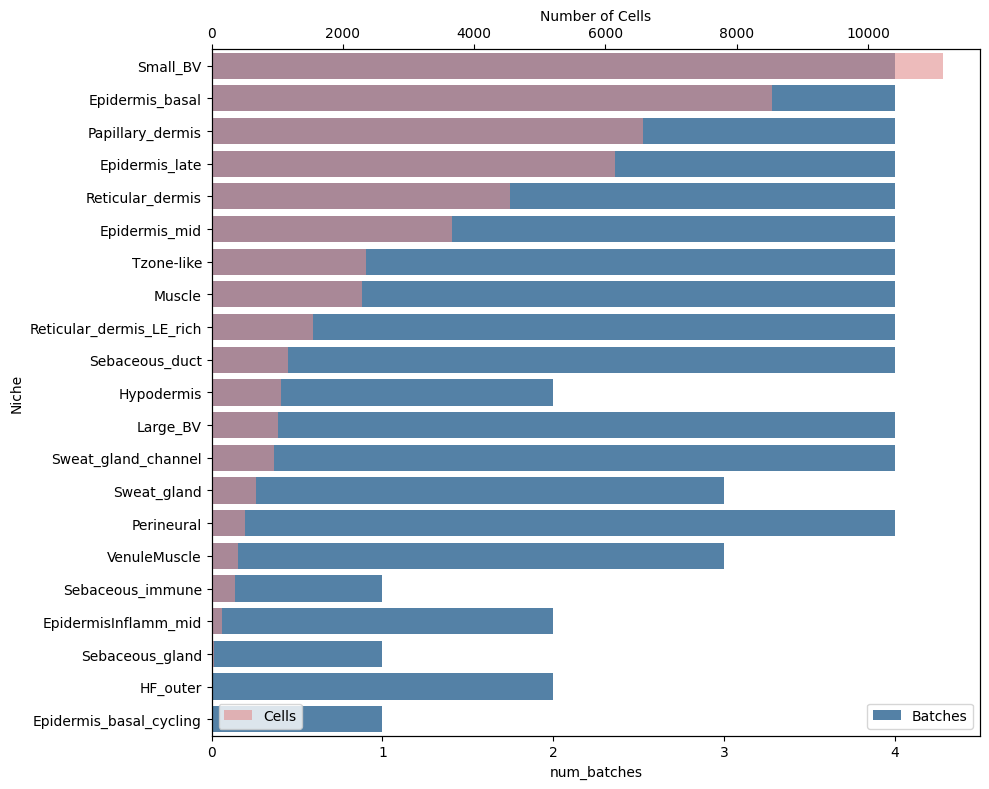

In [35]:
plot_distribution_cells_vs_patients_niche(
        adata,
        label_name='niche19',
        stratify='batch'
        )

In [36]:
data = {
    'Novae Zero-shot': [0.5438202247191011, 0.3647833677194096, 0.5388849316842582, 0.4384274025793926],
    'scGPT-spatial Zero-shot': [0.6963483146067416, 0.5778447865497540, 0.6254048952597932, 0.5617806129524338],
    'Pantheome Zero-shot': [0.820880149812734, 0.7318679574670687, 0.8003626238425177, 0.7402579392594647],
    'Pantheome Linear Probing': [0.8359550561797753, 0.7590858593873988, 0.8297610567894839, 0.7697268062682013],
    'Pantheome LoRA + Linear Probing': [0.8056179775280898, 0.7665449928582765, 0.8393446869131646, 0.7722923311607267]
}

/tmp/ipykernel_2456423/3789567117.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(df.values, labels=df.columns, patch_artist=True)


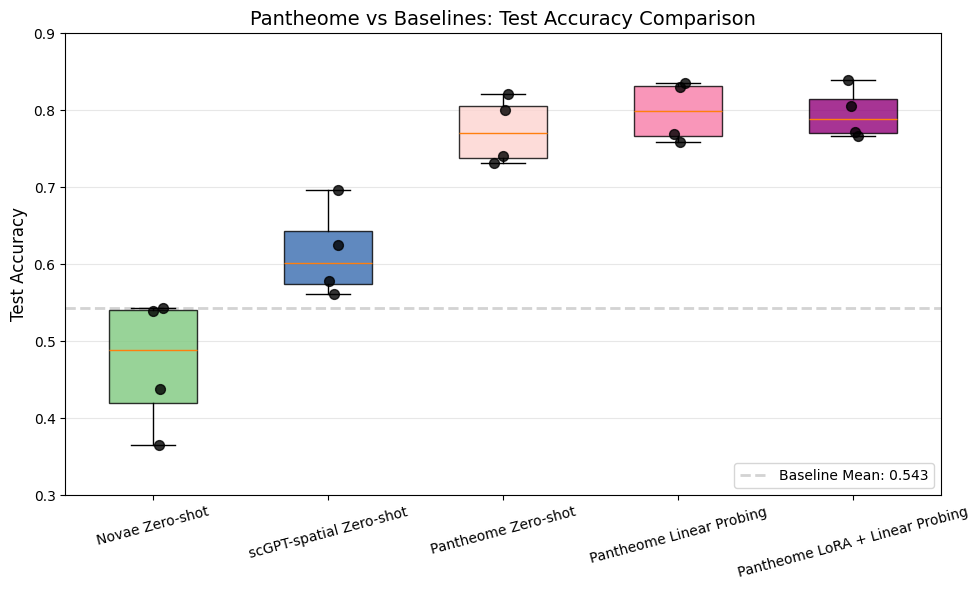

In [38]:
# Create DataFrame
df = pd.DataFrame(data)

# Create the box plot
fig, ax = plt.subplots(figsize=(10, 6))

# Get specific colors from Accent palette (green=0, red=3, blue=4)
accent = sns.color_palette("Accent")
green = accent[0]   # For Novae Zero-shot
blue = accent[4]    # For scGPT-spatial Zero-shot
red = accent[3]     # Reserve for future baselines

# Get three shades from RdPu for Pantheome methods (light to dark)
rdpu = sns.color_palette("RdPu", n_colors=10)
pantheome_light = rdpu[1]   # Pantheome Zero-shot
pantheome_mid = rdpu[4]     # Pantheome Linear Probing  
pantheome_dark = rdpu[8]    # Pantheome LoRA + Linear Probing

# Combine: [Novae, Pantheome Zero-shot, Pantheome LP, Pantheome LoRA+LP]
colors = [green, blue, pantheome_light, pantheome_mid, pantheome_dark]

bp = ax.boxplot(df.values, labels=df.columns, patch_artist=True)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# Scatter points
for i, col in enumerate(df.columns):
    y = df[col]
    x = np.random.normal(i + 1, 0.04, size=len(y))
    ax.scatter(x, y, alpha=0.8, color='black', s=50, zorder=3)

# Calculate mean of means for non-Pantheome baselines
baseline_columns = ['Novae Zero-shot', 'scGPT-spatial Zero-shot']
baseline_mean_of_means = df[baseline_columns].mean().mean()

# Draw horizontal line for baseline mean
ax.axhline(y=baseline_mean_of_means, color='lightgray', linestyle='--', linewidth=2, 
           label=f'Baseline Mean: {baseline_mean_of_means:.3f}', zorder=1)

ax.set_ylabel('Test Accuracy', fontsize=12)
ax.set_title('Pantheome vs Baselines: Test Accuracy Comparison', fontsize=14)
ax.set_ylim(0.3, 0.9)
ax.grid(axis='y', alpha=0.3)
ax.tick_params(axis='x', rotation=15)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

# xhs

In [24]:
train_adata = sc.read_h5ad("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-transfer/data/outer-fold_1/train.h5ad")
test_adata = sc.read_h5ad("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-transfer/data/outer-fold_1/test.h5ad")

adata = ad.concat([train_adata, test_adata], axis=0)
adata

AnnData object with n_obs × n_vars = 1135730 × 4993
    obs: 'sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'lvl5_annotation', 'atlas_status', 'atlas_status_reynolds', 'original_cell_id', 'x_centroid', 'y_centroid', 'Sanger patient ID', 'Drug', 'Timepoint', 'disease_overall', 'baseline_severity', 'info_id6', 'response', 'tech', 'scanvi_predictions2', 'lvl1_new', 'lvl5_annotation_all', 'niche19', 'Site_status_binary2', 'cell_id', 'batch', 'Sanger patient ID from Index', 'Patient ID', 'niche19_cls_idx'
    obsm: 'X_scvi', 'X_umap', 'spatial'
    layers: 'counts'

/tmp/ipykernel_2456423/3950067457.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(label_name)


                     niche19  num_patients  num_cells
0                   Small_BV            19     229710
1           Papillary_dermis            19     148246
2            Epidermis_basal            19     108351
3              Epidermis_mid            19     107906
4             Epidermis_late            19      90797
5                 Tzone-like            19      66183
6           Reticular_dermis            19      65345
7       EpidermisInflamm_mid            19      56986
8                Sweat_gland            15      37149
9        Sweat_gland_channel            19      36512
10                    Muscle            19      33268
11            Sebaceous_duct            18      25546
12                  Large_BV            19      21966
13  Reticular_dermis_LE_rich            19      20143
14                Perineural            19      15502
15                  HF_outer            16      14345
16              VenuleMuscle            16      14131
17                Hypodermis

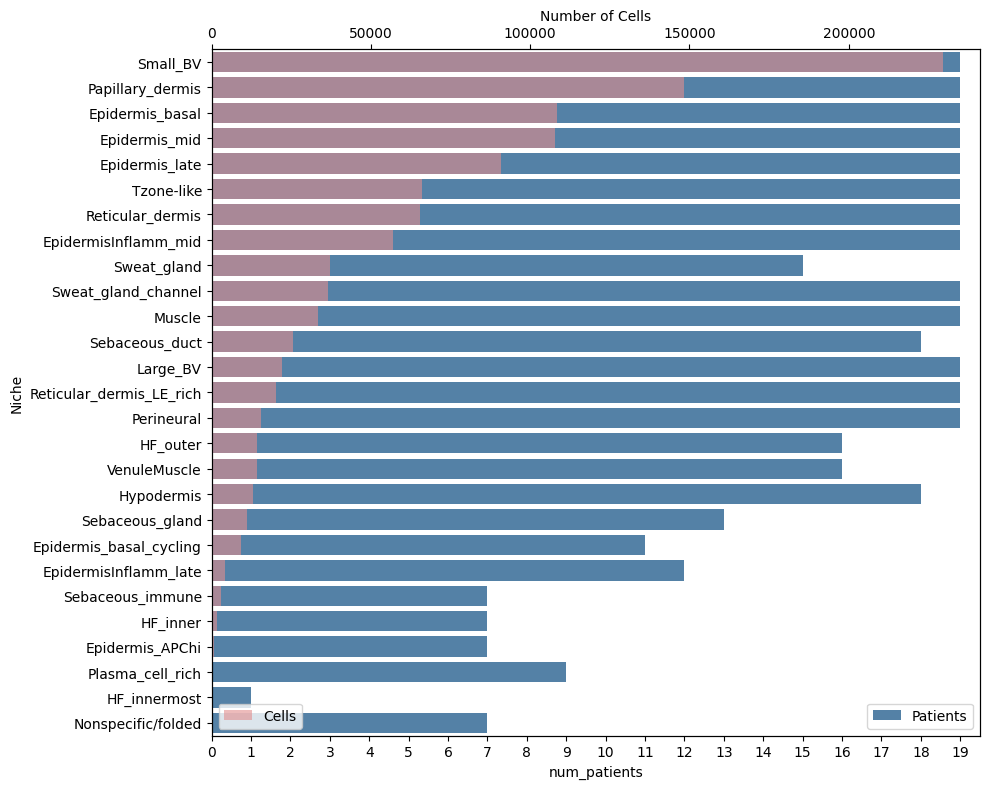

In [25]:
plot_distribution_cells_vs_patients_niche(
        adata,
        label_name='niche19',
        stratify='Patient ID'
        )

In [4]:
data = {
    'TERRA Fine-tuning': [0.84113350945058478, 0.7964583801292135, 0.8182949839017512, 0.8221945544956301],
    'TERRA Linear Probing': [0.8308195632568196, 0.7963833393388584, 0.8398398862960653, 0.8154421629337862],
    'TERRA': [0.782201979570351, 0.7564425938530115, 0.8215225304926687, 0.7939238532049461],
    'scGPT-spatial': [0.6426396283871747, 0.6098890979701326, 0.6710562573421706, 0.6537310079107546],
    'Novae': [0.36277909640122713, 0.2912839812627617, 0.3049672956157271, 0.42761692650334077],
}

data = {
    'TERRA Fine-tuning': [0.84113350945058478, 0.7964583801292135, 0.8182949839017512, 0.8221945544956301],
    'TERRA Linear Probing': [0.8308195632568196, 0.7963833393388584, 0.8398398862960653, 0.8154421629337862],
    'TERRA':                [0.782201979570351,  0.7564425938530115, 0.8215225304926687, 0.7939238532049461],
    'CellPLM':              [0.5735395668793655, 0.5421067381991432, 0.5911647401778074, 0.5920310878774461],
    'Nicheformer':          [0.1875120279841664, 0.2227862967263215, 0.0844773824890139, 0.1840555669374078],
    'scGPT-spatial':        [0.6426396283871747, 0.6098890979701326, 0.6710562573421706, 0.6537310079107546],
    'Novae':                [0.3627790964012271, 0.2912839812627617, 0.3049672956157271, 0.4276169265033407],
}

df = pd.DataFrame(data)
df = df.melt(
    var_name='method',
    value_name='Accuracy',  # or 'ARI' depending on what metric these values represent
    ignore_index=False
).reset_index()
df['dataset'] = 'Xenium Skin'
df

,index,method,Accuracy,dataset
0,0,TERRA Fine-tuning,0.841134,Xenium Skin
1,1,TERRA Fine-tuning,0.796458,Xenium Skin
2,2,TERRA Fine-tuning,0.818295,Xenium Skin
3,3,TERRA Fine-tuning,0.822195,Xenium Skin
4,0,TERRA Linear Probing,0.830820,Xenium Skin
5,1,TERRA Linear Probing,0.796383,Xenium Skin
6,2,TERRA Linear Probing,0.839840,Xenium Skin
7,3,TERRA Linear Probing,0.815442,Xenium Skin
8,0,TERRA,0.782202,Xenium Skin
9,1,TERRA,0.756443,Xenium Skin


/tmp/ipykernel_341684/3752762378.py:57: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
/tmp/ipykernel_341684/3752762378.py:149: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=0.01)


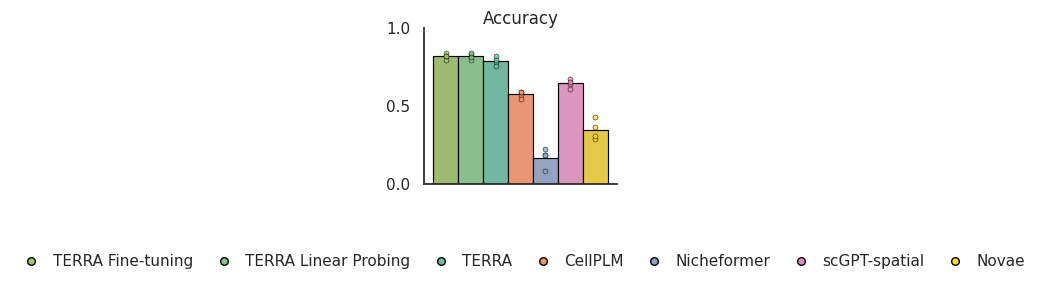

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D
from collections import OrderedDict

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 21,
    "axes.titlesize": 21,
    "axes.labelsize": 21,
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 17,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sns.set(style="white")

# ----------------------------
# Explicit colors (editable)
# ----------------------------
SET2_HEX = [
    "#a1c765",  # TERRA Fine-Tune
    "#84c585", # TERRA Linear Probing
    "#66c2a5",  # TERRA
    "#fc8d62",  # CellPLM
    "#8da0cb",  # Nicheformer
    "#e78ac3",  # scGPT-spatial
    "#ffd92f",  # Novae
]

methods = list(df["method"].unique())
datasets = list(df["dataset"].unique())

METHOD_COLORS = {
    method: SET2_HEX[i]
    for i, method in enumerate(methods)
}

# ----------------------------
# Plot
# ----------------------------
for metric in ["Accuracy"]:

    # Compact figure
    fig, ax = plt.subplots(figsize=(2.5,3))

    BAR_WIDTH = 0.18

    # ---- BARPLOT ----
    sns.barplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        dodge=True,
        ci=None,
        width=BAR_WIDTH,
        palette=METHOD_COLORS,
        edgecolor="black",
        linewidth=0.85,
        ax=ax
    )

    # ---- DOTS (ALIGNED TO BAR CENTERS) ----
    bar_index = 0
    for dataset in datasets:
        for method in methods:

            subset = df[
                (df["dataset"] == dataset) &
                (df["method"] == method)
            ]

            if subset.empty:
                bar_index += 1
                continue

            patch = ax.patches[bar_index]
            x_center = patch.get_x() + patch.get_width() / 2

            ax.scatter(
                np.full(len(subset), x_center),
                subset[metric].values,
                s=3.6**2,
                marker="o",
                facecolor=METHOD_COLORS[method],
                edgecolor="black",
                linewidth=0.45,
                alpha=0.75,
                zorder=10
            )

            bar_index += 1

    # ---- LEGEND (DOT-ONLY, SINGLE ROW) ----
    if ax.legend_ is not None:
        ax.legend_.remove()

    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color="w",
            label=method,
            markerfacecolor=METHOD_COLORS[method],
            markeredgecolor="black",
            markersize=5.5
        )
        for method in methods
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.36),
        ncol=len(legend_handles),
        frameon=False,
        handletextpad=0.4,
        columnspacing=1.0
    )
    ax.set_xticks([])
    ax.set_xticklabels([])

    # ---- AXES ----
    ax.set_title("Accuracy", pad=3)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylim(0.0, 1.0)

    # ---- REMOVE CATEGORY WHITESPACE (CRITICAL) ----
    left = min(p.get_x() for p in ax.patches)
    right = max(p.get_x() + p.get_width() for p in ax.patches)
    ax.set_xlim(left - 0.01, right + 0.01)
    ax.margins(x=0)

    # ---- CLEAN LOOK ----
    sns.despine(ax=ax, top=True, right=True)
    ax.grid(False)

    plt.tight_layout(pad=0.01)
    plt.subplots_adjust(bottom=0.36)

    # ---- SAVE ----
    plt.savefig(
        "niche_transfer.svg",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [6]:
data = {
      'TERRA Fine-tuning':    [0.9303603301044878, 0.9344330117041012, 0.9445461269597252, 0.9475854685321156],
      'TERRA Linear Probing': [0.707642, 0.72322, 0.71172, 0.739923],
      'TERRA':                [0.7011965721660183, 0.7164724880223139, 0.7035546982639845, 0.7334333467712623],
      'CellPLM':              [0.5735395668793655, 0.5421067381991432, 0.5911647401778074, 0.5920310878774461],
      'Nicheformer':          [0.1875120279841664, 0.2227862967263215, 0.0844773824890139, 0.1840555669374078],
      'scGPT-spatial':        [0.9345677661344794, 0.9301410631113958, 0.9358878043828226, 0.9403686398392735],
      'Novae':                [0.5166052217488595, 0.500783387383059,  0.4459195660686574, 0.5850257413441013],
  }

df = pd.DataFrame(data)
df = df.melt(
    var_name='method',
    value_name='Accuracy',  # or 'ARI' depending on what metric these values represent
    ignore_index=False
).reset_index()
df['dataset'] = 'Xenium Skin'
df

,index,method,Accuracy,dataset
0,0,TERRA Fine-tuning,0.930360,Xenium Skin
1,1,TERRA Fine-tuning,0.934433,Xenium Skin
2,2,TERRA Fine-tuning,0.944546,Xenium Skin
3,3,TERRA Fine-tuning,0.947585,Xenium Skin
4,0,TERRA Linear Probing,0.707642,Xenium Skin
5,1,TERRA Linear Probing,0.723220,Xenium Skin
6,2,TERRA Linear Probing,0.711720,Xenium Skin
7,3,TERRA Linear Probing,0.739923,Xenium Skin
8,0,TERRA,0.701197,Xenium Skin
9,1,TERRA,0.716472,Xenium Skin


/tmp/ipykernel_341684/1154670517.py:57: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
/tmp/ipykernel_341684/1154670517.py:149: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=0.01)


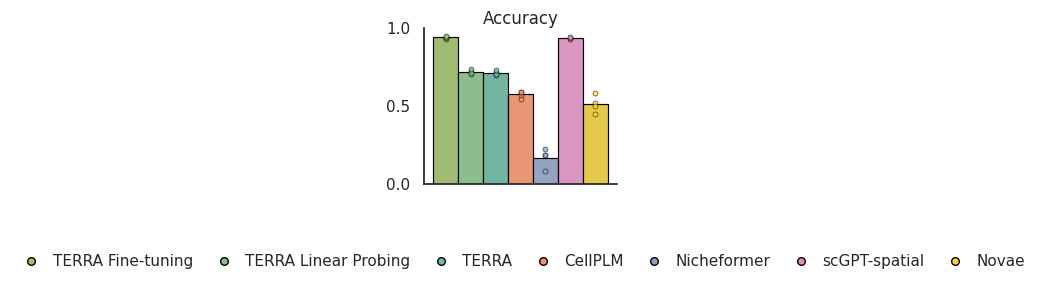

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D
from collections import OrderedDict

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 21,
    "axes.titlesize": 21,
    "axes.labelsize": 21,
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 17,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sns.set(style="white")

# ----------------------------
# Explicit colors (editable)
# ----------------------------
SET2_HEX = [
    "#a1c765",  # TERRA Fine-Tune
    "#84c585", # TERRA Linear Probing
    "#66c2a5",  # TERRA
    "#fc8d62",  # CellPLM
    "#8da0cb",  # Nicheformer
    "#e78ac3",  # scGPT-spatial
    "#ffd92f",  # Novae
]

methods = list(df["method"].unique())
datasets = list(df["dataset"].unique())

METHOD_COLORS = {
    method: SET2_HEX[i]
    for i, method in enumerate(methods)
}

# ----------------------------
# Plot
# ----------------------------
for metric in ["Accuracy"]:

    # Compact figure
    fig, ax = plt.subplots(figsize=(2.5,3))

    BAR_WIDTH = 0.18

    # ---- BARPLOT ----
    sns.barplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        dodge=True,
        ci=None,
        width=BAR_WIDTH,
        palette=METHOD_COLORS,
        edgecolor="black",
        linewidth=0.85,
        ax=ax
    )

    # ---- DOTS (ALIGNED TO BAR CENTERS) ----
    bar_index = 0
    for dataset in datasets:
        for method in methods:

            subset = df[
                (df["dataset"] == dataset) &
                (df["method"] == method)
            ]

            if subset.empty:
                bar_index += 1
                continue

            patch = ax.patches[bar_index]
            x_center = patch.get_x() + patch.get_width() / 2

            ax.scatter(
                np.full(len(subset), x_center),
                subset[metric].values,
                s=3.6**2,
                marker="o",
                facecolor=METHOD_COLORS[method],
                edgecolor="black",
                linewidth=0.45,
                alpha=0.75,
                zorder=10
            )

            bar_index += 1

    # ---- LEGEND (DOT-ONLY, SINGLE ROW) ----
    if ax.legend_ is not None:
        ax.legend_.remove()

    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color="w",
            label=method,
            markerfacecolor=METHOD_COLORS[method],
            markeredgecolor="black",
            markersize=5.5
        )
        for method in methods
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.36),
        ncol=len(legend_handles),
        frameon=False,
        handletextpad=0.4,
        columnspacing=1.0
    )
    ax.set_xticks([])
    ax.set_xticklabels([])

    # ---- AXES ----
    ax.set_title("Accuracy", pad=3)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylim(0.0, 1.0)

    # ---- REMOVE CATEGORY WHITESPACE (CRITICAL) ----
    left = min(p.get_x() for p in ax.patches)
    right = max(p.get_x() + p.get_width() for p in ax.patches)
    ax.set_xlim(left - 0.01, right + 0.01)
    ax.margins(x=0)

    # ---- CLEAN LOOK ----
    sns.despine(ax=ax, top=True, right=True)
    ax.grid(False)

    plt.tight_layout(pad=0.01)
    plt.subplots_adjust(bottom=0.36)

    # ---- SAVE ----
    plt.savefig(
        "/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/figures/cell_transfer.svg",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()